In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [19]:
df=pd.read_csv('train.csv')
print(df)

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

In [20]:
print(df.head())
print(df.shape)
print(df.describe())
print(df.isna().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

In [21]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
None


In [22]:
print(f"Mean is {df['Age'].mean()}")
print(f"Median is {df['Age'].median()}")

Mean is 29.69911764705882
Median is 28.0


In [23]:
passclass=df.groupby('Pclass')['Age'].median()
print(passclass)

Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64


In [24]:
df_clean = df.copy()

df_clean['Age'] = df_clean['Age'].fillna(
    df_clean.groupby('Pclass')['Age'].transform('median')
)
print(df_clean['Age'].isna().sum())
print(df_clean.shape)
print(df_clean.groupby('Pclass')['Age'].median())

0
(891, 12)
Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64


In [25]:
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])
print(df_clean['Embarked'].value_counts())
print(df_clean['Embarked'].isna().sum())

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64
0


In [26]:
df_clean['HasCabin']=df_clean['Cabin'].notna()
df_clean=df_clean.drop(columns=['Cabin'])
print(df_clean['HasCabin'].value_counts())
print(df_clean.groupby('HasCabin')['Survived'].mean())
print(df_clean.shape)

HasCabin
False    687
True     204
Name: count, dtype: int64
HasCabin
False    0.299854
True     0.666667
Name: Survived, dtype: float64
(891, 12)


In [27]:
df_clean['Sex'] = df_clean['Sex'].astype('category')
df_clean['Embarked'] = df_clean['Embarked'].astype('category')
print(df_clean.dtypes)

PassengerId       int64
Survived          int64
Pclass            int64
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
HasCabin           bool
dtype: object


In [28]:
sursex=df_clean.groupby('Sex')['Survived'].mean()
surclass=df_clean.groupby('Pclass')['Survived'].mean()
mean=df_clean["Survived"].mean()

print(sursex)
print(surclass)
print(mean)

print(df_clean.groupby(['Sex','Pclass'])['Survived'].mean())


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64
0.3838383838383838
Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64


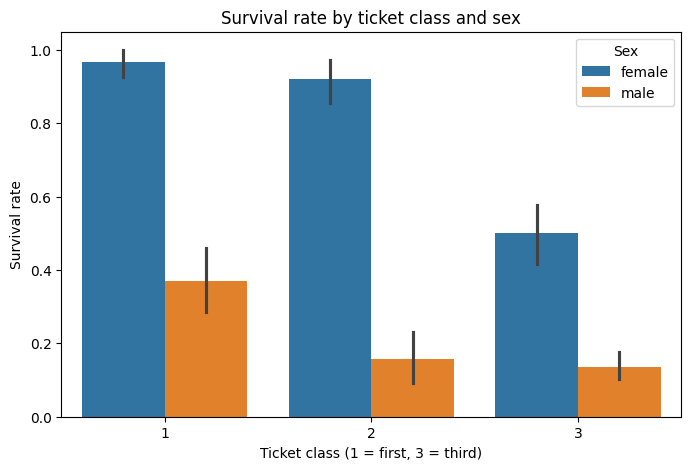

In [29]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_clean, x='Pclass', y='Survived', hue='Sex')
plt.title('Survival rate by ticket class and sex')
plt.xlabel('Ticket class (1 = first, 3 = third)')
plt.ylabel('Survival rate')
plt.show()

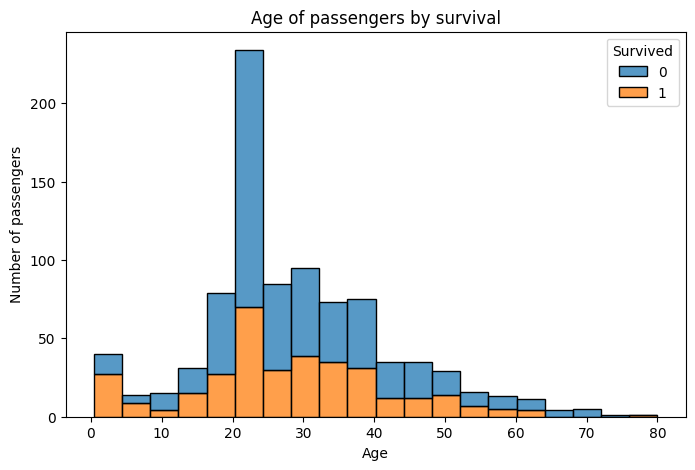

In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x='Age', hue='Survived', bins=20, multiple='stack')
plt.title('Age of passengers by survival')
plt.xlabel('Age')
plt.ylabel('Number of passengers')
plt.show()

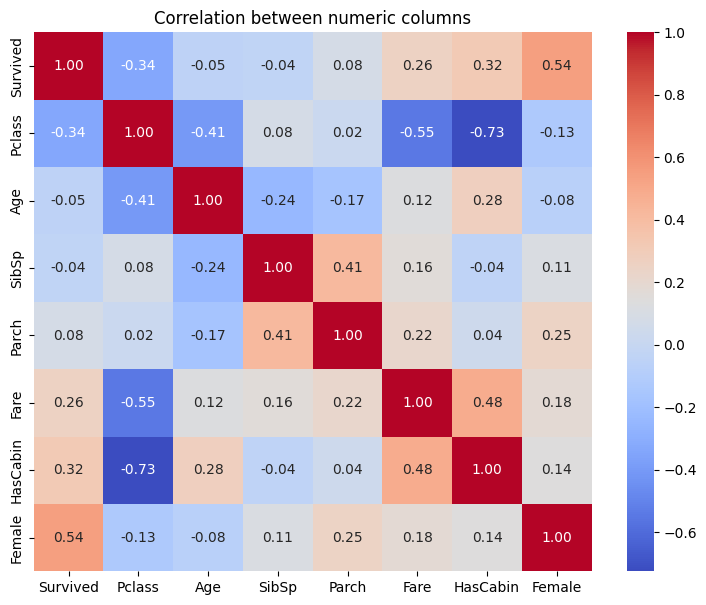

In [31]:
df_clean['Female'] = (df_clean['Sex'] == 'female').astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(
    df_clean.drop(columns='PassengerId').corr(numeric_only=True),
    annot=True, cmap='coolwarm', fmt='.2f'
)
plt.title('Correlation between numeric columns')
plt.show()

##Findings

# Out of 891 passengers, about 38.4% survived. The biggest difference was by sex: 74.2% of women survived against only 18.9% of men. Ticket class also mattered a lot. 63.0% of first class survived, 47.3% of second class, and 24.2% of third class.

# Looking at sex and class together gives the clearest picture. First-class women had the highest survival rate at 96.8%, and third-class men had the lowest at 13.5%. Third-class women (50%) actually survived more often than first-class men (36.9%), so being a woman seemed to help more than having an expensive ticket. The age chart shows that most of the youngest children survived, while there are very few survivors above 60. The tall spike around age 24 isn't a real pattern. It comes from how I filled in the 177 missing ages with the median age of each ticket class.

# On the correlation heatmap, being female has the strongest link with survival (0.54), followed by ticket class (-0.34, because a higher class number means a cheaper ticket), having a cabin recorded (0.32) and fare (0.26). Having a cabin recorded is strongly tied to class (-0.73), so it mostly reflects first-class passengers and doesn't mean the cabin itself helped.

# A few limits to keep in mind. Correlation doesn't show cause, so these patterns tell us who survived and not why. About a fifth of the ages were filled in by me, and 77% of the cabin values were missing, so I replaced them with a yes/no column. The groups are also different sizes, so some rates, like first-class men or third-class women, are less certain than others.